<a href="https://colab.research.google.com/github/sahumathsrupesh-glitch/EDA-HOUSE-PRICE/blob/main/House_Price_EDA_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# House Price EDA (Simple Version)
**Dataset:** Ames Housing, `train.csv` (1,460 houses, 81 columns)  
**Goal:** Find out what makes a house price go up or down, using EDA only.

**EDA** = looking at data with numbers and graphs to understand it.

### Step 0: Upload the file (Colab only)


In [ ]:
# Colab only: choose train.csv from your computer
from google.colab import files
files.upload()

Saving train.csv to train (1).csv


{'train (1).csv': b'Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice\n1,60,RL,65,8450,Pave,NA,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,

### Step 1: Load the data
**What it does:** reads the file and shows its size and first 5 rows.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("train.csv")
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


**Result:** 1,460 houses (rows) and 81 columns (details of each house).

### Step 2: Missing values
**What it does:** counts empty cells in each column.

In [ ]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Columns with missing values:", len(missing))
missing

Columns with missing values: 19


,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81


**Result:** 19 columns have missing values.  
Most of them are **not really missing**. For example, PoolQC is empty when the house has no pool. So we should not delete them.

### Step 3: Basic statistics of SalePrice
**What it does:** finds the average (mean), middle value (median) and skewness.

In [ ]:
print("Mean   :", round(df["SalePrice"].mean()))
print("Median :", df["SalePrice"].median())
print("Skewness:", round(df["SalePrice"].skew(), 2))

Mean   : 180921
Median : 163000.0
Skewness: 1.88


**Result:** mean (180,921) is bigger than median (163,000), so the data is **right skewed**.  
A few very expensive houses pull the average up.

### Step 4: Distribution of SalePrice
**What it does:** draws a histogram of the price, and again after taking log.

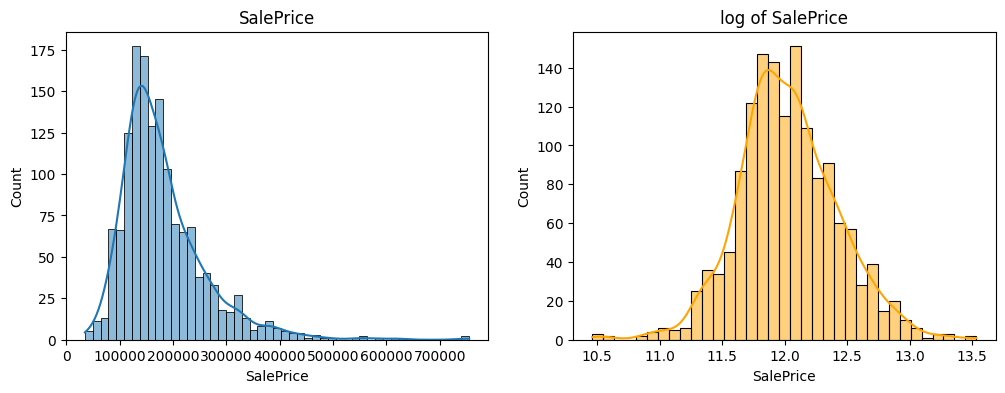

Skewness after log: 0.12


In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(df["SalePrice"], kde=True)
plt.title("SalePrice")

plt.subplot(1, 2, 2)
sns.histplot(np.log(df["SalePrice"]), kde=True, color="orange")
plt.title("log of SalePrice")

plt.show()
print("Skewness after log:", round(np.log(df["SalePrice"]).skew(), 2))

**Result:** Price is skewed to the right (skewness 1.88). After **log** it becomes almost normal (skewness 0.12).  
Log reduces the effect of very large values.

### Step 5: Which features affect price the most?
**What it does:** correlation shows how strongly a feature moves with price (value from -1 to +1).

In [ ]:
corr = df.corr(numeric_only=True)["SalePrice"].sort_values(ascending=False)
corr.head(11)

,SalePrice
SalePrice,1.000000
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


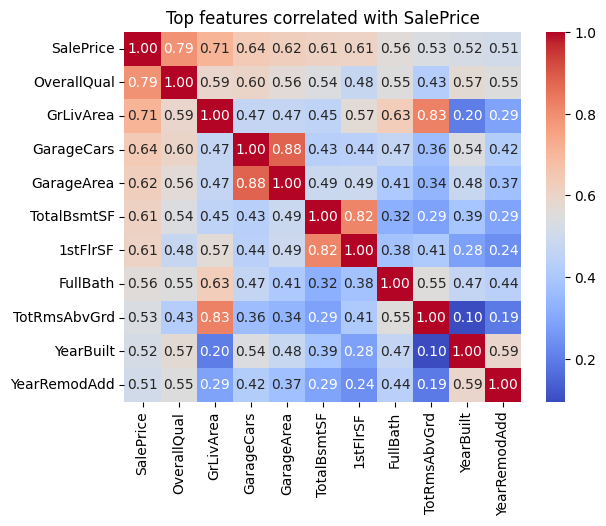

In [ ]:
top10 = corr.head(11).index
sns.heatmap(df[top10].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Top features correlated with SalePrice")
plt.show()

**Result:** The top two are **OverallQual (0.79)** and **GrLivArea (0.71)**.  
Better quality and bigger living area means higher price.  
*Correlation does not prove cause.*

### Step 6: Quality and price
**What it does:** compares price for each quality rating from 1 to 10.

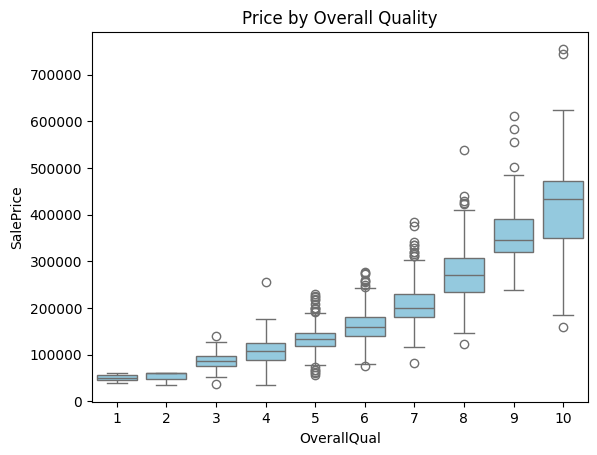

In [ ]:
sns.boxplot(x="OverallQual", y="SalePrice", data=df, color="skyblue")
plt.title("Price by Overall Quality")
plt.show()

**Result:** Price goes up steadily with quality.

### Step 7: Neighborhood and price
**What it does:** shows the median price of each neighborhood.

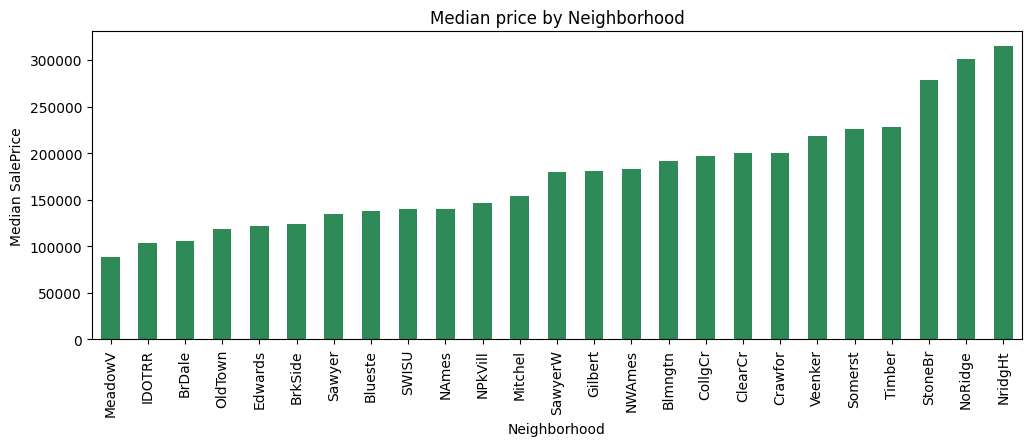

In [ ]:
median_price = df.groupby("Neighborhood")["SalePrice"].median().sort_values()
median_price.plot(kind="bar", figsize=(12, 4), color="seagreen")
plt.title("Median price by Neighborhood")
plt.ylabel("Median SalePrice")
plt.show()

**Result:** NridgHt, NoRidge and StoneBr are the most expensive. MeadowV and IDOTRR are the cheapest.

### Step 8: Outliers
**What it does:** looks for houses that do not follow the normal pattern.

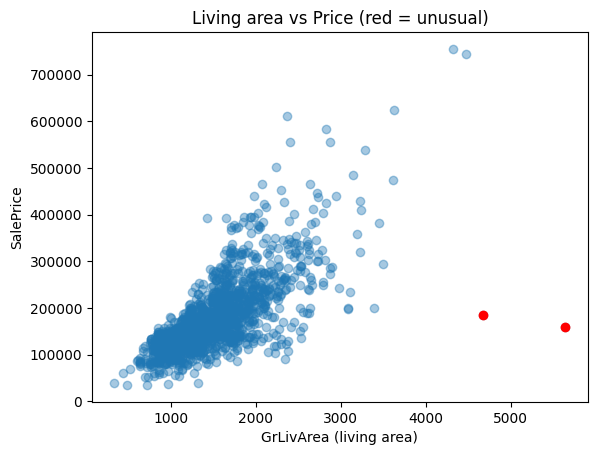

,Id,GrLivArea,SalePrice,SaleCondition
523,524,4676,184750,Partial
1298,1299,5642,160000,Partial


In [ ]:
odd = (df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)

plt.scatter(df["GrLivArea"], df["SalePrice"], alpha=0.4)
plt.scatter(df[odd]["GrLivArea"], df[odd]["SalePrice"], color="red")
plt.xlabel("GrLivArea (living area)")
plt.ylabel("SalePrice")
plt.title("Living area vs Price (red = unusual)")
plt.show()

df[odd][["Id", "GrLivArea", "SalePrice", "SaleCondition"]]

**Result:** Two houses are very large (over 4,000 sq ft) but sold cheap. Both are *Partial* sales (not a normal sale), so we remove them.  
Other expensive houses are real luxury homes, so we keep them.

In [ ]:
df = df[~odd]
print("Rows after removing 2 unusual houses:", len(df))
print("Correlation GrLivArea vs SalePrice:", round(df["GrLivArea"].corr(df["SalePrice"]), 3))

Rows after removing 2 unusual houses: 1458
Correlation GrLivArea vs SalePrice: 0.735


**Result:** Correlation between area and price improves after removing them (0.709 to 0.735).

### Step 9: Cleaning the data
**What it does:** checks duplicates and fills missing values.

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

# NA here means "this feature is not in the house" -> fill with "None"
absent = ["PoolQC", "MiscFeature", "Alley", "Fence", "MasVnrType", "FireplaceQu",
          "GarageType", "GarageFinish", "GarageQual", "GarageCond",
          "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
df[absent] = df[absent].fillna("None")
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(0)

# Really missing values
df["LotFrontage"] = df["LotFrontage"].fillna(df["LotFrontage"].median())
df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode()[0])

print("Missing values left:", df.isnull().sum().sum())

Duplicate rows: 0
Missing values left: 0


**Result:**
- No duplicate rows.
- "Feature not present" columns are filled with `"None"` (or 0 for numbers).
- LotFrontage is filled with the median, and Electrical with its most common value.
- Missing values are now 0.

### Conclusion
1. House price is right skewed, and log makes it almost normal.
2. **OverallQual** and **GrLivArea** affect price the most.
3. Higher quality means higher price.
4. Some neighborhoods are much more expensive than others.
5. Two unusual sales were removed.
6. Many "missing" values only mean the feature is absent.

**Limitation:** This is only EDA (no prediction model), and the data is from Ames, Iowa only.